In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mma3001_project.thermal import (extract_segments, fit_segments, prediction_errors,
                                     first_order_response, time_to_reach)

recon = pd.read_csv("../data/processed/sensor869_reconstructed.csv", index_col=0, parse_dates=True)
events = pd.read_csv("../results/daily_events.csv", index_col=0, parse_dates=True)
test_start = pd.Timestamp("2024-06-01")
warm = extract_segments(recon["temp_c"], events["hvac_on_h"], length_h=2, pick="min")
cool = extract_segments(recon["temp_c"], events["hvac_off_h"], length_h=6, pick="max")
print(len(warm), "warm-up and", len(cool), "cool-down segments")

103 warm-up and 106 cool-down segments


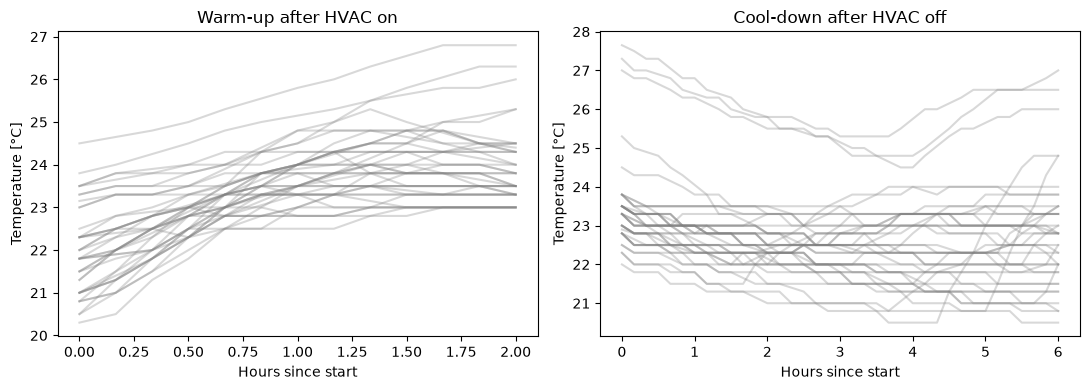

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, segs, title in [(axes[0], warm, "Warm-up after HVAC on"),
                        (axes[1], cool, "Cool-down after HVAC off")]:
    for _, t, y in segs[:40]:
        ax.plot(t, y, color="grey", alpha=0.3)
    ax.set_title(title); ax.set_xlabel("Hours since start"); ax.set_ylabel("Temperature [°C]")
plt.tight_layout(); plt.show()

In [3]:
fits = {"warm-up": fit_segments(warm, guess=(23.5, 0.5)),
        "cool-down": fit_segments(cool, guess=(20.0, 4.0))}
dev_fits = {name: f[f.index < test_start] for name, f in fits.items()}
summary = pd.DataFrame({
    name: {"days": len(f),
           "tau median [h]": f["tau"].median(),
           "tau IQR [h]": f["tau"].quantile(0.75) - f["tau"].quantile(0.25),
           "T_inf median [°C]": f["y_inf"].median(),
           "fit RMSE median [°C]": f["rmse"].median(),
           "tau at bound [%]": 100 * f["at_bound"].mean()}
    for name, f in dev_fits.items()}).T
summary.round(2)

,days,tau median [h],tau IQR [h],T_inf median [°C],fit RMSE median [°C],tau at bound [%]
warm-up,90.0,0.77,0.98,24.20,0.16,7.78
cool-down,93.0,3.88,4.47,21.03,0.10,9.68


In [5]:
params = {name: f[["y_inf", "tau"]].median() for name, f in dev_fits.items()}
rows = []
for name, segs in [("warm-up", warm), ("cool-down", cool)]:
    test_segs = [s for s in segs if s[0] >= test_start]
    model_err, base_err = prediction_errors(test_segs, params[name]["y_inf"], params[name]["tau"])
    rows.append({"model": name, "test days": len(test_segs),
                 "first-order RMSE [°C]": np.sqrt(np.mean(model_err ** 2)),
                 "no-change RMSE [°C]": np.sqrt(np.mean(base_err ** 2))})
validation = pd.DataFrame(rows).set_index("model")
validation.round(2)

,test days,first-order RMSE [°C],no-change RMSE [°C]
model,,,
warm-up,13,0.59,2.88
cool-down,13,0.65,1.83


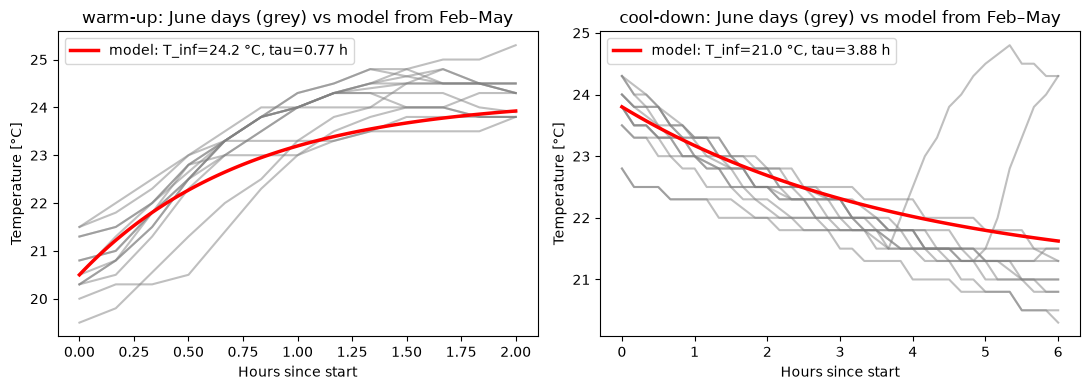

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, segs, hours) in zip(axes, [("warm-up", warm, 2), ("cool-down", cool, 6)]):
    test_segs = [s for s in segs if s[0] >= test_start]
    for _, t, y in test_segs:
        ax.plot(t, y, color="grey", alpha=0.5)
    t_fine = np.linspace(0, hours, 100)
    y0 = np.median([y[0] for _, _, y in test_segs])
    p = params[name]
    ax.plot(t_fine, first_order_response(t_fine, p["y_inf"], p["tau"], y0), "r", lw=2.5,
            label=f"model: T_inf={p['y_inf']:.1f} °C, tau={p['tau']:.2f} h")
    ax.set_title(f"{name}: June days (grey) vs model from Feb–May")
    ax.set_xlabel("Hours since start"); ax.set_ylabel("Temperature [°C]"); ax.legend()
plt.tight_layout(); plt.show()

In [7]:
COMFORT = 22.5
night_low = dev_fits["warm-up"]["y0"].median()
occupied_temp = dev_fits["cool-down"]["y0"].median()
w, c = params["warm-up"], params["cool-down"]
warm_up_h = time_to_reach(night_low, COMFORT, w["y_inf"], w["tau"])
hold_h = time_to_reach(occupied_temp, COMFORT, c["y_inf"], c["tau"])
print(f"Typical overnight low: {night_low:.1f} °C; typical temperature at switch-off: {occupied_temp:.1f} °C")
print(f"Warm-up time to {COMFORT} °C: {warm_up_h*60:.0f} min")
print(f"Stays above {COMFORT} °C after switch-off for: {hold_h*60:.0f} min")

Typical overnight low: 21.0 °C; typical temperature at switch-off: 23.5 °C
Warm-up time to 22.5 °C: 29 min
Stays above 22.5 °C after switch-off for: 121 min


In [8]:
os.makedirs("../results", exist_ok=True)
summary.to_csv("../results/thermal_parameters.csv")
validation.to_csv("../results/thermal_validation.csv")
pd.Series({"comfort_c": COMFORT, "warm_up_h": warm_up_h, "hold_h": hold_h,
           "warm_T_inf": w["y_inf"], "warm_tau_h": w["tau"],
           "cool_T_inf": c["y_inf"], "cool_tau_h": c["tau"]}).to_csv("../results/schedule_inputs.csv")